# Task 5 – Training my root segmentation model

I trained a residual U-Net to detect root pixels in Petri dish images. I used the prepared 512 × 512 patches from Task 4, so this notebook starts with the finished dataset instead of preprocessing everything again.

My training set has 9,600 patches, and my validation set has 612 patches from the `val_` images in Y2B_25. I kept that validation set separate from training.

In [12]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# IMPORTANT: use tf_keras consistently on this server
import tf_keras as keras
from tf_keras import backend as K
from tf_keras import layers
from tf_keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
# REQUIREMENT: Do not add code from Tasks 2 or 4
# REQUIREMENT: All dataset prep must already be finalized.

patch_size = 512
patch_dir = "/home/y2a/dataset"

DATASET_DIR = Path(patch_dir)

train_image_dir = DATASET_DIR / "train_images" / "train"
train_mask_dir  = DATASET_DIR / "train_masks" / "train"

val_image_dir = DATASET_DIR / "val_images" / "val"
val_mask_dir  = DATASET_DIR / "val_masks" / "val"

for folder in [
    train_image_dir,
    train_mask_dir,
    val_image_dir,
    val_mask_dir
]:
    assert folder.exists(), f"Missing folder: {folder}"

train_image_paths = sorted(train_image_dir.glob("*.png"))
val_image_paths = sorted(val_image_dir.glob("*.png"))

assert len(train_image_paths) == 9600, (
    f"Expected 9600 training patches, found {len(train_image_paths)}"
)

assert len(val_image_paths) == 612, (
    f"Expected 612 validation patches, found {len(val_image_paths)}"
)

# Validation must remain Y25 val ONLY
assert all(
    p.name.lower().startswith("y25__val_")
    for p in val_image_paths
), "Validation contains non-Y25-validation files."

print("Training patches:", len(train_image_paths))
print("Validation patches:", len(val_image_paths))
print("Patch size:", patch_size)

print("✅ Correct finalized dataset found.")
print("✅ Frozen Y25 validation set confirmed.")

Training patches: 9600
Validation patches: 612
Patch size: 512
✅ Correct finalized dataset found.
✅ Frozen Y25 validation set confirmed.


## Model and training setup

I used a residual U-Net with group normalization. My loss combines Dice, binary cross-entropy and a soft connectivity loss, because the roots are thin and I wanted to keep their structure as well as possible.

I also balanced the training batches by including patches with different amounts of root pixels. The validation patches are only used to check performance.

In [14]:
def f1(y_true, y_pred):
    """Calculate F1 from rounded predicted and ground-truth pixels."""
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision
    
    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    
    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [15]:
# ============================================================
# DICE + BCE + SOFT-clDice
# ============================================================

def dice_loss(y_true, y_pred):

    """Measure how much the predicted mask overlaps the real mask."""
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)

    intersection = K.sum(
        y_true_f * y_pred_f
    )

    dice = (
        2.0 * intersection
        + K.epsilon()
    ) / (
        K.sum(y_true_f)
        + K.sum(y_pred_f)
        + K.epsilon()
    )

    return 1.0 - dice



def dice_bce_loss(y_true, y_pred):

    """Combine Dice loss with binary cross-entropy."""
    bce = K.mean(
        K.binary_crossentropy(
            y_true,
            y_pred
        )
    )

    dice = dice_loss(
        y_true,
        y_pred
    )

    return (
        dice
        + 0.3 * bce
    )



def soft_erode(x):

    """Approximate erosion for the differentiable skeleton loss."""
    vertical = -tf.nn.max_pool2d(
        -x,
        ksize=[1, 3, 1, 1],
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    horizontal = -tf.nn.max_pool2d(
        -x,
        ksize=[1, 1, 3, 1],
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    return tf.minimum(
        vertical,
        horizontal
    )



def soft_dilate(x):

    """Approximate dilation for the differentiable skeleton loss."""
    return tf.nn.max_pool2d(
        x,
        ksize=[1, 3, 3, 1],
        strides=[1, 1, 1, 1],
        padding="SAME"
    )



def soft_open(x):

    """Apply differentiable opening to a mask."""
    return soft_dilate(
        soft_erode(x)
    )



def soft_skeletonize(
    x,
    iterations=10
):

    """Estimate a soft skeleton by repeating erosion and opening."""
    opened = soft_open(x)

    skeleton = tf.nn.relu(
        x - opened
    )

    for _ in range(iterations):

        x = soft_erode(x)

        opened = soft_open(x)

        delta = tf.nn.relu(
            x - opened
        )

        skeleton = (
            skeleton
            + tf.nn.relu(
                delta
                - skeleton * delta
            )
        )

    return skeleton



def soft_cldice_loss(
    y_true,
    y_pred
):

    """Penalize disconnected root structures using soft skeletons."""
    skel_true = soft_skeletonize(
        y_true,
        iterations=10
    )

    skel_pred = soft_skeletonize(
        y_pred,
        iterations=10
    )

    smooth = K.epsilon()

    topology_precision = (
        K.sum(
            skel_pred * y_true
        )
        + smooth
    ) / (
        K.sum(skel_pred)
        + smooth
    )

    topology_sensitivity = (
        K.sum(
            skel_true * y_pred
        )
        + smooth
    ) / (
        K.sum(skel_true)
        + smooth
    )

    cldice = (
        2.0
        * topology_precision
        * topology_sensitivity
        + smooth
    ) / (
        topology_precision
        + topology_sensitivity
        + smooth
    )

    return 1.0 - cldice



def root_segmentation_loss(
    y_true,
    y_pred
):

    """Combine pixel overlap, BCE, and root connectivity losses."""
    region_loss = dice_bce_loss(
        y_true,
        y_pred
    )

    topology_loss = soft_cldice_loss(
        y_true,
        y_pred
    )

    return (
        region_loss
        + 0.2 * topology_loss
    )

In [16]:
# ============================================================
# RESIDUAL U-NET + GROUP NORMALIZATION
# ============================================================

@keras.utils.register_keras_serializable(package="RootSeg")
class GroupNormalization(layers.Layer):

    """Normalize convolution features in groups."""
    def __init__(
        self,
        groups=8,
        epsilon=1e-5,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.groups = groups
        self.epsilon = epsilon


    def build(self, input_shape):

        channels = int(input_shape[-1])

        if channels % self.groups != 0:
            raise ValueError(
                f"Channels ({channels}) must be divisible "
                f"by groups ({self.groups})."
            )

        self.gamma = self.add_weight(
            name="gamma",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )

        self.beta = self.add_weight(
            name="beta",
            shape=(channels,),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)


    def call(self, inputs):

        shape = tf.shape(inputs)

        batch = shape[0]
        height = shape[1]
        width = shape[2]
        channels = shape[3]

        x = tf.reshape(
            inputs,
            [
                batch,
                height,
                width,
                self.groups,
                channels // self.groups
            ]
        )

        mean, variance = tf.nn.moments(
            x,
            axes=[1, 2, 4],
            keepdims=True
        )

        x = (
            x - mean
        ) / tf.sqrt(
            variance + self.epsilon
        )

        x = tf.reshape(
            x,
            shape
        )

        return (
            x * self.gamma
            + self.beta
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "groups": self.groups,
            "epsilon": self.epsilon
        })

        return config



def residual_block(
    x,
    filters,
    groups=8
):

    """Build a residual convolution block for the U-Net."""
    shortcut = x

    x = layers.Conv2D(
        filters,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = GroupNormalization(
        groups=groups
    )(x)

    x = layers.Activation(
        "relu"
    )(x)


    x = layers.Conv2D(
        filters,
        (3, 3),
        padding="same",
        use_bias=False
    )(x)

    x = GroupNormalization(
        groups=groups
    )(x)


    # Match shortcut channels when necessary
    if int(shortcut.shape[-1]) != filters:

        shortcut = layers.Conv2D(
            filters,
            (1, 1),
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = GroupNormalization(
            groups=groups
        )(shortcut)


    x = layers.Add()([
        x,
        shortcut
    ])

    x = layers.Activation(
        "relu"
    )(x)

    return x



def residual_unet_model(
    IMG_HEIGHT,
    IMG_WIDTH,
    IMG_CHANNELS
):

    """Construct the residual U-Net for 512-pixel root masks."""
    inputs = layers.Input(
        (
            IMG_HEIGHT,
            IMG_WIDTH,
            IMG_CHANNELS
        )
    )


    # Encoder 1
    c1 = residual_block(
        inputs,
        16
    )

    p1 = layers.MaxPooling2D(
        (2, 2)
    )(c1)


    # Encoder 2
    c2 = residual_block(
        p1,
        32
    )

    p2 = layers.MaxPooling2D(
        (2, 2)
    )(c2)


    # Encoder 3
    c3 = residual_block(
        p2,
        64
    )

    p3 = layers.MaxPooling2D(
        (2, 2)
    )(c3)


    # Encoder 4
    c4 = residual_block(
        p3,
        128
    )

    p4 = layers.MaxPooling2D(
        (2, 2)
    )(c4)


    # Bottleneck
    c5 = residual_block(
        p4,
        256
    )


    # Decoder 1
    u6 = layers.Conv2DTranspose(
        128,
        (2, 2),
        strides=(2, 2),
        padding="same"
    )(c5)

    u6 = layers.Concatenate()([
        u6,
        c4
    ])

    c6 = residual_block(
        u6,
        128
    )


    # Decoder 2
    u7 = layers.Conv2DTranspose(
        64,
        (2, 2),
        strides=(2, 2),
        padding="same"
    )(c6)

    u7 = layers.Concatenate()([
        u7,
        c3
    ])

    c7 = residual_block(
        u7,
        64
    )


    # Decoder 3
    u8 = layers.Conv2DTranspose(
        32,
        (2, 2),
        strides=(2, 2),
        padding="same"
    )(c7)

    u8 = layers.Concatenate()([
        u8,
        c2
    ])

    c8 = residual_block(
        u8,
        32
    )


    # Decoder 4
    u9 = layers.Conv2DTranspose(
        16,
        (2, 2),
        strides=(2, 2),
        padding="same"
    )(c8)

    u9 = layers.Concatenate()([
        u9,
        c1
    ])

    c9 = residual_block(
        u9,
        16
    )


    outputs = layers.Conv2D(
        1,
        (1, 1),
        activation="sigmoid"
    )(c9)


    return keras.Model(
        inputs=inputs,
        outputs=outputs
    )

In [17]:
# Build U-Net
# REQUIREMENT: Model summary must be visible

# ============================================================
# BUILD AND COMPILE RESIDUAL U-NET
# ============================================================

keras.backend.clear_session()

IMG_HEIGHT = patch_size
IMG_WIDTH = patch_size
IMG_CHANNELS = 1


model = residual_unet_model(
    IMG_HEIGHT,
    IMG_WIDTH,
    IMG_CHANNELS
)


model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=root_segmentation_loss,

    # DO NOT CHANGE.
    # This is the required BUas F1 function.
    metrics=[f1]
)


model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 512, 512, 1)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 512, 512, 16)         144       ['input_1[0][0]']             
                                                                                                  
 group_normalization (Group  (None, 512, 512, 16)         32        ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 512, 512, 16)         0         ['group_normalization[0][0

In [18]:
# ============================================================
# TRAINING PIPELINE
# 1 sparse + 1 medium + 1 dense + 1 empty per batch
# ============================================================

BATCH_SIZE = 4
AUTOTUNE = tf.data.AUTOTUNE

VALID_EXTENSIONS = {".png"}


train_image_paths = sorted([
    p
    for p in train_image_dir.iterdir()
    if p.suffix.lower() in VALID_EXTENSIONS
])

train_mask_paths = [
    train_mask_dir / p.name
    for p in train_image_paths
]


assert len(train_image_paths) == 9600
assert len(train_mask_paths) == 9600

assert all(
    p.exists()
    for p in train_mask_paths
), "Some training masks are missing."



def load_pair(
    image_path,
    mask_path
):

    # Image
    """Read and normalize a matching image and root-mask patch."""
    image = tf.io.read_file(
        image_path
    )

    image = tf.io.decode_png(
        image,
        channels=1
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    image.set_shape([
        patch_size,
        patch_size,
        1
    ])


    # Mask
    mask = tf.io.read_file(
        mask_path
    )

    mask = tf.io.decode_png(
        mask,
        channels=1
    )

    mask = tf.cast(
        mask > 127,
        tf.float32
    )

    mask.set_shape([
        patch_size,
        patch_size,
        1
    ])

    return image, mask



# ------------------------------------------------------------
# Measure root density of every training patch
# ------------------------------------------------------------

root_fractions = []

for p in train_mask_paths:

    mask = tf.io.read_file(
        str(p)
    )

    mask = tf.io.decode_png(
        mask,
        channels=1
    )

    mask = tf.cast(
        mask > 127,
        tf.float32
    )

    root_fractions.append(
        float(
            tf.reduce_mean(mask).numpy()
        )
    )


root_fractions = np.array(
    root_fractions
)


empty_idx = np.where(
    root_fractions == 0
)[0]


sparse_idx = np.where(
    (root_fractions > 0)
    &
    (root_fractions <= 0.003)
)[0]


medium_idx = np.where(
    (root_fractions > 0.003)
    &
    (root_fractions <= 0.01)
)[0]


dense_idx = np.where(
    root_fractions > 0.01
)[0]


print(
    "Empty:",
    len(empty_idx)
)

print(
    "Sparse:",
    len(sparse_idx)
)

print(
    "Medium:",
    len(medium_idx)
)

print(
    "Dense:",
    len(dense_idx)
)



# ------------------------------------------------------------
# Build 2400 finite batches
# Each batch has one item from every density category
# ------------------------------------------------------------

NUM_BATCHES = (
    len(train_image_paths)
    // BATCH_SIZE
)

rng = np.random.default_rng(
    42
)



def cycle_sample(
    indices,
    n,
    rng
):

    """Cycle through one patch group to build balanced batches."""
    indices = np.array(
        indices,
        dtype=np.int64
    )

    output = []

    while len(output) < n:

        shuffled = rng.permutation(
            indices
        )

        output.extend(
            shuffled.tolist()
        )

    return np.array(
        output[:n],
        dtype=np.int64
    )



sparse_epoch = cycle_sample(
    sparse_idx,
    NUM_BATCHES,
    rng
)

medium_epoch = cycle_sample(
    medium_idx,
    NUM_BATCHES,
    rng
)

dense_epoch = cycle_sample(
    dense_idx,
    NUM_BATCHES,
    rng
)

empty_epoch = cycle_sample(
    empty_idx,
    NUM_BATCHES,
    rng
)



batch_indices = np.column_stack([
    sparse_epoch,
    medium_epoch,
    dense_epoch,
    empty_epoch
])


# Randomize position inside each batch
for row in batch_indices:
    rng.shuffle(row)



batch_image_paths = np.array([
    [
        str(train_image_paths[i])
        for i in row
    ]
    for row in batch_indices
])


batch_mask_paths = np.array([
    [
        str(train_mask_paths[i])
        for i in row
    ]
    for row in batch_indices
])



# Each dataset element initially represents ONE COMPLETE BATCH.
grouped_ds = tf.data.Dataset.from_tensor_slices((
    batch_image_paths,
    batch_mask_paths
))


# Shuffle complete groups, not individual patches.
grouped_ds = grouped_ds.shuffle(
    buffer_size=NUM_BATCHES,
    seed=42,
    reshuffle_each_iteration=True
)


# Flatten groups -> load image/mask pairs -> rebuild batches of 4.
train_ds = grouped_ds.unbatch()

train_ds = train_ds.map(
    load_pair,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.batch(
    BATCH_SIZE,
    drop_remainder=True
)

train_ds = train_ds.prefetch(
    AUTOTUNE
)


print(
    "Training batches:",
    NUM_BATCHES
)

print(
    "Samples per epoch:",
    NUM_BATCHES * BATCH_SIZE
)

print(
    "✅ Each batch contains:"
    " 1 sparse + 1 medium +"
    " 1 dense + 1 empty."
)

Empty: 4800
Sparse: 1031
Medium: 1540
Dense: 2229
Training batches: 2400
Samples per epoch: 9600
✅ Each batch contains: 1 sparse + 1 medium + 1 dense + 1 empty.


In [19]:
# Setup a generator for validation

VAL_BATCH_SIZE = 16

val_image_paths = sorted([
    p for p in val_image_dir.iterdir()
    if p.suffix.lower() in VALID_EXTENSIONS
])

val_mask_paths = [
    val_mask_dir / p.name
    for p in val_image_paths
]

assert len(val_image_paths) == 612
assert len(val_mask_paths) == 612

assert all(
    p.exists()
    for p in val_mask_paths
), "Some validation masks are missing."

assert all(
    p.name.lower().startswith("y25__val_")
    for p in val_image_paths
), "Validation contains non-Y25-val files."


val_ds = tf.data.Dataset.from_tensor_slices((
    [str(p) for p in val_image_paths],
    [str(p) for p in val_mask_paths]
))

val_ds = val_ds.map(
    load_pair,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.batch(
    VAL_BATCH_SIZE,
    drop_remainder=False
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

print("Validation patches:", len(val_image_paths))
print(
    "Validation batches:",
    int(np.ceil(
        len(val_image_paths) / VAL_BATCH_SIZE
    ))
)

print("✅ Validation remains Y25 val only.")

Validation patches: 612
Validation batches: 39
✅ Validation remains Y25 val only.


In [20]:
# Sanity check before expensive training

sample_images, sample_masks = next(
    iter(train_ds)
)

print(
    "Training image batch:",
    sample_images.shape
)

print(
    "Training mask batch:",
    sample_masks.shape
)

print(
    "Image range:",
    float(tf.reduce_min(sample_images)),
    "to",
    float(tf.reduce_max(sample_images))
)

print(
    "Mask values:",
    np.unique(sample_masks.numpy())
)

assert sample_images.shape[1:] == (
    512, 512, 1
)

assert sample_masks.shape[1:] == (
    512, 512, 1
)

assert set(
    np.unique(sample_masks.numpy())
).issubset({0.0, 1.0})

print("✅ Data pipeline ready for training.")

Training image batch: (4, 512, 512, 1)
Training mask batch: (4, 512, 512, 1)
Image range: 0.0 to 0.8941176533699036
Mask values: [0. 1.]
✅ Data pipeline ready for training.


In [21]:
# EarlyStopping + best-model checkpoint


# EarlyStopping + separate BatchNorm checkpoint
# ============================================================
# CALLBACKS
# ============================================================

checkpoint_path = (
    "best_resunet_groupnorm_sparseaware.weights.h5"
)


early_stop = EarlyStopping(
    monitor="val_f1",
    mode="max",
    patience=8,
    restore_best_weights=True,
    verbose=1
)


checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_f1",
    mode="max",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)


cb = [
    early_stop,
    checkpoint
]

In [22]:
# This is where the magic happens
# REQUIREMENT: The epoch logs must be visible showing validation loss and validation f1.

# ============================================================
# TRAIN
# ============================================================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=cb,
    verbose=1
)

Epoch 1/100
2400/2400 [==============================] - ETA: 0s - loss: 0.5380 - f1: 0.6770     
Epoch 1: val_f1 improved from -inf to 0.76070, saving model to best_resunet_groupnorm_sparseaware.weights.h5
2400/2400 [==============================] - 258s 102ms/step - loss: 0.5380 - f1: 0.6770 - val_loss: 0.3588 - val_f1: 0.7607
Epoch 2/100
2400/2400 [==============================] - ETA: 0s - loss: 0.2453 - f1: 0.7943  
Epoch 2: val_f1 did not improve from 0.76070
2400/2400 [==============================] - 244s 102ms/step - loss: 0.2453 - f1: 0.7943 - val_loss: 0.3123 - val_f1: 0.7262
Epoch 3/100
2400/2400 [==============================] - ETA: 0s - loss: 0.2195 - f1: 0.8081  
Epoch 3: val_f1 improved from 0.76070 to 0.78790, saving model to best_resunet_groupnorm_sparseaware.weights.h5
2400/2400 [==============================] - 244s 101ms/step - loss: 0.2195 - f1: 0.8081 - val_loss: 0.2254 - val_f1: 0.7879
Epoch 4/100
2400/2400 [==============================] - ETA: 0s - loss

## Saving the model

I saved the trained model as an `.h5` file. I later used my full name in the filename, so I added the next cell to make that filename consistent with the inference notebook. This only renames the saved file; it does not train or change the model.

In [26]:
# REQUIREMENT: Save your model, it is a deliverable
# REQUIREMENT: naming convention 'studentname_studentnumber_unet_model_patchsizepx.h5'
example_file_name = f'nika_244258_unet_model_{512}px.h5'
print(example_file_name)
model.save(example_file_name)

nika_244258_unet_model_512px.h5


/usr/local/lib/python3.12/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
from pathlib import Path

original_model_file = Path("nika_244258_unet_model_512px.h5")
final_model_file = Path("NikaSoleimanzadeh_244258_unet_model_512px.h5")

if original_model_file.exists():
    # Use the model that was just saved; replace an older copy if needed.
    original_model_file.replace(final_model_file)
elif not final_model_file.exists():
    raise FileNotFoundError("I couldn't find either model filename.")

print("Final model file:", final_model_file.resolve())

## Validation results

I monitored the validation F1 during training and used early stopping to restore the best weights. The saved training log reports a best validation F1 of **0.8024** at epoch 13. I left the original template result cells and plots below unchanged.

In [23]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
best_val_loss = min(history.history['val_loss'])
best_val_f1 = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1: {best_val_f1}")

Best validation loss: 0.2020515650510788
Best validation f1: 0.802433431148529


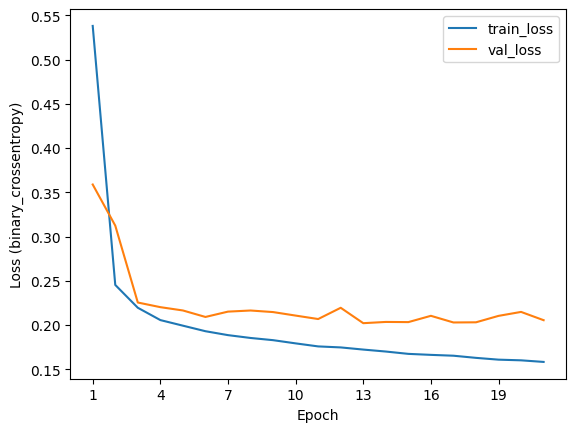

In [24]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = np.arange(1, len(loss) + 1)

plt.plot(epochs, loss, label='train_loss')
plt.plot(epochs, val_loss, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (binary_crossentropy)')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

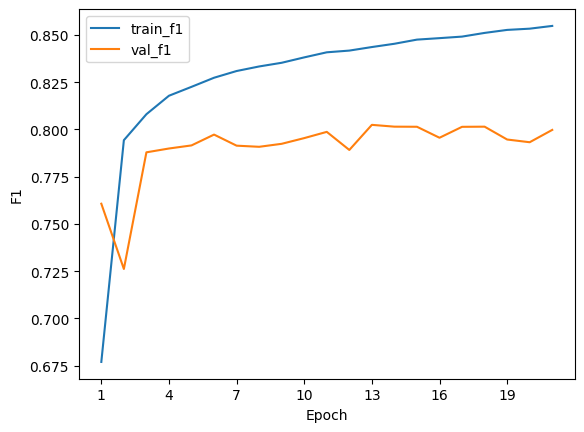

In [25]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
train_f1 = history.history['f1']
val_f1 = history.history['val_f1']

epochs = np.arange(1, len(train_f1) + 1)

plt.plot(epochs, train_f1, label='train_f1')
plt.plot(epochs, val_f1, label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))